# Chapter 3 notebook: a validated dielectric unit-cell library

**Topic ID:** `ms-07-unit-cell`. This notebook runs a full-wave, frequency-domain
Maxwell calculation for a **one-dimensional, lossless, nonmagnetic dielectric
ridge grating under TE illumination** ($E_y$, $k_y=0$). It uses the original
course module `simulations/unit_cell_te.py`, NumPy, SciPy, and Matplotlib.
Download the Chapter 3 source bundle or clone the repository to retain that module.

Predict first: will changing only the ridge width provide every transmission
phase while keeping high transmission? The computed library will answer for
this particular idealized geometry. It does not represent cylindrical pillars, material dispersion, fabrication, a finite array, or arbitrary polarization.

Convention: $e^{-i\omega t}$, $e^{i\mathbf{k}\cdot\mathbf{r}}$; incidence from
$z<0$; centered ridge $|x|<w/2$, $0<z<h$. Lengths are in micrometers.
The incident $E_y$ is one at $z=0$; $r_m$ is at $z=0$ and $t_m$ at $z=h$.
The routine publishing build displays these saved outputs and does not run a solver.

This notebook exports a zeroth-order library. An early domain check rejects additional open or grazing channels before any solver run. Oblique-incidence edits are supported while only m=0 remains open in both media; the Fresnel benchmark uses the edited angle and indices.


In [1]:
from pathlib import Path
import sys, json, csv, hashlib, platform, html
from dataclasses import replace, asdict
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next((p for p in [Path.cwd(), *list(Path.cwd().parents)[:3]]
             if (p/'simulations/unit_cell_te.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the Chapter 3 source ZIP, or run from the repository notebooks folder; simulations/unit_cell_te.py is required.')
sys.path.insert(0, str(ROOT/'simulations'))
from unit_cell_te import Cell, solve_cell, film_reference, deembed_te, phase_error_deg, sample_ey, SOLVER_VERSION

# EDIT THESE PARAMETERS. Changing them defines a new experiment.
REFERENCE = Cell(period_um=0.65, width_um=0.325, height_um=0.60,
                 wavelength_um=1.55, n_ridge=2.4, n_gap=1.0,
                 n_incident=1.0, n_substrate=1.5, angle_deg=0.0)
def require_single_order_library(cell):
    cell.validate()
    alpha0=cell.n_incident*np.sin(np.deg2rad(cell.angle_deg))
    extent=int(np.ceil((max(cell.n_incident,cell.n_substrate)+abs(alpha0))*cell.period_um/cell.wavelength_um))+1
    orders=np.arange(-extent,extent+1)
    alpha=alpha0+orders*cell.wavelength_um/cell.period_um
    extra=(orders!=0)&((abs(alpha)<=cell.n_incident+1e-12)|(abs(alpha)<=cell.n_substrate+1e-12))
    if np.any(extra) or abs(alpha0)>=cell.n_substrate-1e-12:
        raise ValueError('This library requires only m=0 open in both exterior media, with no grazing channel. '
                         'Choose a smaller period/angle or use an all-order dataset and target-order selection; '
                         'total transmission cannot qualify a zeroth-order phase.')
require_single_order_library(REFERENCE)
WIDTHS_UM = np.round(np.linspace(0.08, 0.57, 50), 8)
M_LIBRARY, M_CHECK = 24, 32
POWER_TOL, COMPLEX_TOL, PHASE_TOL_DEG = 5e-4, 5e-4, 0.05
MIN_T_FOR_SELECTION, TARGET_TOL_DEG = 0.8, 5.0
ENABLE_WIDGETS = False
DATA = ROOT/'data/chapter-03'
DATA.mkdir(parents=True, exist_ok=True)

def table(headers, rows):
    def escaped(value):
        return html.escape(f'{value:.6g}' if isinstance(value,(float,np.floating)) else str(value))
    display(HTML('<table><thead><tr>'+''.join('<th>'+escaped(x)+'</th>' for x in headers)+
                 '</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escaped(x)+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))

plt.rcParams.update({'figure.dpi': 125, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| SciPy', scipy.__version__, '| Matplotlib', matplotlib.__version__)
print('Solver:', SOLVER_VERSION, '| harmonics:', 2*M_LIBRARY+1, 'checked against', 2*M_CHECK+1)
table(['Parameter', 'Value'], asdict(REFERENCE).items())

Python 3.12.1 | NumPy 2.4.6 | SciPy 1.18.1 | Matplotlib 3.11.1
Solver: te-ridge-1.0 | harmonics: 49 checked against 65


Parameter,Value
period_um,0.65
width_um,0.325
height_um,0.6
wavelength_um,1.55
n_ridge,2.4
n_gap,1
n_incident,1
n_substrate,1.5
angle_deg,0


## 1. Validate an answer that is known independently

At $h=0$, the structure becomes a flat interface and $r=(q_i-q_t)/(q_i+q_t)$,
$t=2q_i/(q_i+q_t)$. At $w=0$ or $w=\Lambda$, the layer is a uniform film.
The independent scalar Fabry-Perot formula provides **complex** amplitudes,
not only $R+T$. Check both endpoint films at three angles and three heights.
These limits test references and signs; they do not by themselves validate
a patterned ridge. Order convergence and a separate implementation comparison
are needed later.

In [2]:
benchmark_rows=[]
max_complex_error=0.0
for angle in [0.,20.,45.]:
    for height in [0.,0.17,0.60]:
        for width, index in [(0.,REFERENCE.n_gap),(REFERENCE.period_um,REFERENCE.n_ridge)]:
            cell=replace(REFERENCE,angle_deg=angle,height_um=height,width_um=width)
            result=solve_cell(cell,8)
            ra,ta=film_reference(cell,index)
            error=max(abs(result['r'][8]-ra),abs(result['t'][8]-ta))
            max_complex_error=max(max_complex_error,error)
            assert error < 1e-10
            assert result['balance_error'] < 1e-10
        benchmark_rows.append([angle,height,error,result['balance_error']])
flat=solve_cell(replace(REFERENCE,height_um=0),8)
alpha0=REFERENCE.n_incident*np.sin(np.deg2rad(REFERENCE.angle_deg))
qi=np.sqrt(complex(REFERENCE.n_incident**2-alpha0**2))
qt=np.sqrt(complex(REFERENCE.n_substrate**2-alpha0**2))
expected_r=(qi-qt)/(qi+qt);expected_t=2*qi/(qi+qt)
assert abs(flat['r'][8]-expected_r)<1e-10 and abs(flat['t'][8]-expected_t)<1e-10
print('18 uniform-film/interface checks passed; maximum complex-amplitude error:',max_complex_error)
print(f'Flat interface at {REFERENCE.angle_deg:g} degrees: r=',flat['r'][8], 't=',flat['t'][8], 'R=',flat['R_total'],'T=',flat['T_total'])
table(['Angle (deg)','Height (um)','Full-width film complex error','Power-balance error'],benchmark_rows)

18 uniform-film/interface checks passed; maximum complex-amplitude error: 8.82085992141607e-15
Flat interface at 0 degrees: r= (-0.20000000000000018+1.6627429638464806e-17j) t= (0.7999999999999998+1.6627429638464806e-17j) R= 0.04000000000000007 T= 0.9599999999999995


Angle (deg),Height (um),Full-width film complex error,Power-balance error
0,0,1.11022e-16,1.11022e-16
0,0.17,1.03042e-15,2.22045e-16
0,0.6,3.71095e-15,4.44089e-16
20,0,1.38778e-16,1.11022e-16
20,0.17,4.57757e-16,1.11022e-16
20,0.6,2.12108e-15,4.44089e-16
45,0,1.11022e-16,2.22045e-16
45,0.17,1.92613e-15,1.11022e-16
45,0.6,8.82086e-15,0


## 2. A small power residual is not convergence

The TE Fourier eigenproblem is
$[\epsilon_{m-n}-\alpha_m^2\delta_{mn}]W=WQ^2$, with
$\alpha_m=n_i\sin\theta_i+m\lambda_0/\Lambda$.
The rectangle has exact coefficients
$\epsilon_\ell=n_g^2\delta_{\ell0}+(n_r^2-n_g^2)f\,\mathrm{sinc}(\ell f)$,
where $f=w/\Lambda$ and $\mathrm{sinc}(u)=\sin(\pi u)/(\pi u)$.
Both fields and their normal derivatives are matched at each face.

Compare retained half-orders $M$ against $M=48$ at $w=0.325$ um.
The power residual can already be small at $M=0$ while complex transmission
is still inaccurate. The library below checks every width at $M=24$ and $32$.

In [3]:
reference_high=solve_cell(REFERENCE,48)
convergence=[]
for M in [0,1,2,4,8,12,16,24,32]:
    result=solve_cell(REFERENCE,M)
    convergence.append([M,2*M+1,result['T_total'],
                        abs(result['t'][M]-reference_high['t'][48]),
                        abs(phase_error_deg(result['t'][M],reference_high['t'][48])),
                        result['balance_error']])
table(['M','Harmonics','T total','Complex t error vs M=48','Phase error (deg)','Power residual'],convergence)
assert convergence[-1][3] < COMPLEX_TOL

M,Harmonics,T total,Complex t error vs M=48,Phase error (deg),Power residual
0,1,0.857092,0.320439,24.9143,3.33067e-16
1,3,0.781572,0.00577386,0.456786,0
2,5,0.781485,0.00365669,0.288128,0
4,9,0.780658,0.000607304,0.047913,6.66134e-16
8,17,0.780526,8.3745e-05,0.00661087,0
12,25,0.780512,2.51138e-05,0.00198286,2.22045e-16
16,33,0.780508,1.04584e-05,0.000825823,2.22045e-16
24,49,0.780507,2.83594e-06,0.000223952,0
32,65,0.780506,9.64869e-07,7.6198e-05,2.22045e-16


## 3. See the field that produces the response

The modal coefficients reconstruct the incident, reflected, internal, and
transmitted fields. The black outlines mark the periodic ridges and substrate
boundary. $|E_y/E_{\rm inc}|^2$ is a squared field amplitude, **not** transmitted
power or electromagnetic energy density. Closed harmonics contribute near the
ridge even though they carry no outgoing far-field power in the exterior.

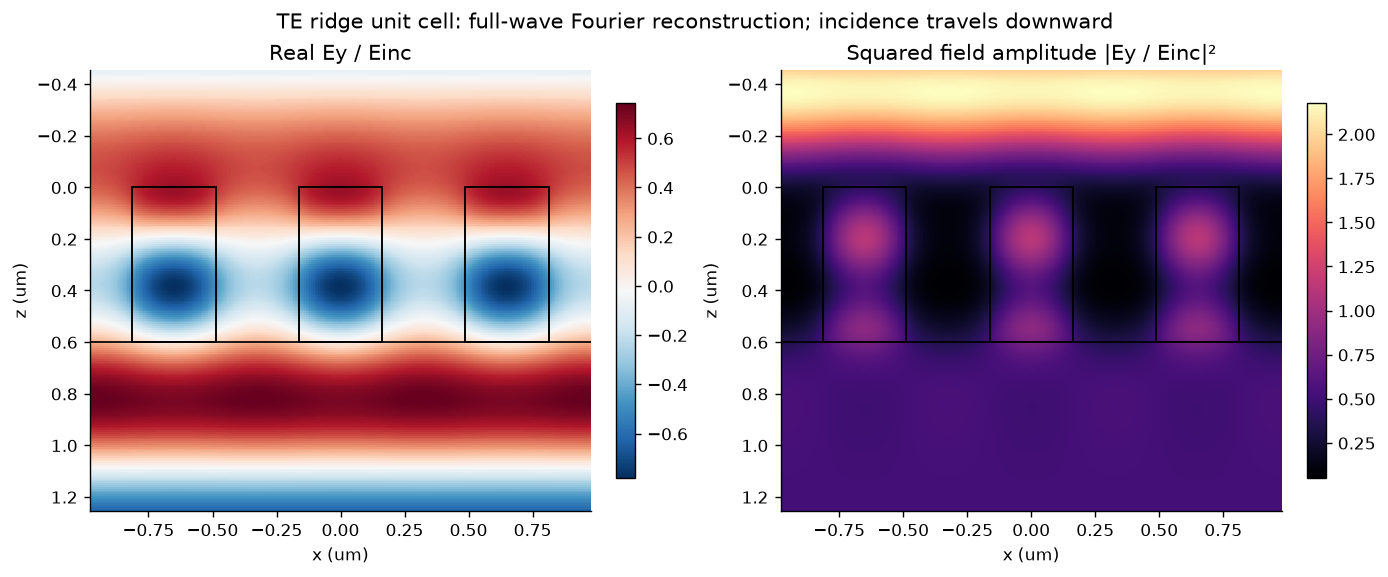

In [4]:
result=solve_cell(REFERENCE,M_LIBRARY)
x=np.linspace(-1.5*REFERENCE.period_um,1.5*REFERENCE.period_um,281)
z=np.linspace(-0.45,REFERENCE.height_um+0.65,241)
field=sample_ey(REFERENCE,result,x,z)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,values,title,cmap in zip(axes,[field.real,abs(field)**2],['Real Ey / Einc','Squared field amplitude |Ey / Einc|²'],['RdBu_r','magma']):
    image=ax.pcolormesh(x,z,values,shading='auto',cmap=cmap)
    fig.colorbar(image,ax=ax,shrink=0.85)
    for center in [-REFERENCE.period_um,0,REFERENCE.period_um]:
        ax.add_patch(plt.Rectangle((center-REFERENCE.width_um/2,0),REFERENCE.width_um,REFERENCE.height_um,fill=False,lw=1.1,color='black'))
    ax.axhline(REFERENCE.height_um,color='black',lw=1)
    ax.set(xlabel='x (um)',ylabel='z (um)',title=title)
    ax.invert_yaxis()
fig.suptitle('TE ridge unit cell: full-wave Fourier reconstruction; incidence travels downward')
plt.show()

## 4. Build the library and preserve its evidence

At this period and wavelength only $m=0$ propagates in either exterior medium.
For this TE field convention,
$R_m=\mathrm{Re}(q_{i,m})|r_m|^2/q_{i,0}$ and
$T_m=\mathrm{Re}(q_{t,m})|t_m|^2/q_{i,0}$.
The spectral roots are positive real or positive imaginary.

Each row stores complex amplitudes as real/imaginary parts, powers, numerical
residuals, and the change when increasing $M$. The metadata records geometry,
conventions, phase reference planes, source hash, environment, thresholds,
and validity domain. The JSON and CSV are regenerated by this cell. Only
rows passing the stated checks are accepted. These are convergence tests
between finite truncations, not rigorous error bounds.

In [5]:
rows=[]
for width in WIDTHS_UM:
    cell=replace(REFERENCE,width_um=float(width))
    low,high=solve_cell(cell,M_LIBRARY),solve_cell(cell,M_CHECK)
    t,r=low['t'][M_LIBRARY],low['r'][M_LIBRARY]
    dt=abs(t-high['t'][M_CHECK])
    dp=max(abs(low['T_total']-high['T_total']),abs(low['R_total']-high['R_total']))
    dphi=abs(phase_error_deg(t,high['t'][M_CHECK]))
    accepted=bool(dt<COMPLEX_TOL and dp<POWER_TOL and dphi<PHASE_TOL_DEG and low['balance_error']<1e-8)
    rows.append(dict(width_um=float(width),r_real=float(r.real),r_imag=float(r.imag),
                     t_real=float(t.real),t_imag=float(t.imag),T=low['T_total'],R=low['R_total'],
                     phase_deg=float(np.rad2deg(np.angle(t))),balance_error=low['balance_error'],
                     solve_residual=low['solve_residual'],delta_t=float(dt),delta_power=float(dp),
                     delta_phase_deg=float(dphi),accepted=accepted))
assert all(row['accepted'] for row in rows)
t_values=np.array([complex(row['t_real'],row['t_imag']) for row in rows])
T_values=np.array([row['T'] for row in rows])
unwrapped=np.rad2deg(np.unwrap(np.angle(t_values)))
phase_span=float(np.ptp(unwrapped))
metadata=dict(schema='metasurface-unit-cell-library-v1',topic_id='ms-07-unit-cell',
              model='1D centered rectangular dielectric ridge, TE Ey, ky=0, single uniform-height layer',
              solver=SOLVER_VERSION,source_sha256=hashlib.sha256((ROOT/'simulations/unit_cell_te.py').read_bytes()).hexdigest(),
              parameters=asdict(REFERENCE),varying_parameter='width_um',units='micrometers and degrees',
              time_convention='exp(-i omega t)',spatial_convention='exp(i k.r)',
              phase_references={'r':'z=0','t':'z=height','incident_Ey':'one at z=0'},
              material_model='positive real constant indices; nonmagnetic, lossless, nondispersive',
              harmonics=2*M_LIBRARY+1,check_harmonics=2*M_CHECK+1,
              thresholds=dict(delta_complex_t=COMPLEX_TOL,delta_power=POWER_TOL,delta_phase_deg=PHASE_TOL_DEG,power_residual=1e-8),
              environment={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__},
              validation_scope='uniform-film analytic limits, width-wise harmonic refinements; see validation.json for additional audits',
              unwrapped_phase_span_deg=phase_span,
              limitations=['No TM or conical incidence','No 2D lattice or finite array','No absorption or dispersion','No fabricated-device validation','No full 360-degree phase coverage for this width sweep'])
library=dict(metadata=metadata,rows=rows)
(DATA/'response-library.json').write_text(json.dumps(library,indent=2)+'\n',encoding='utf-8')
with (DATA/'response-library.csv').open('w',newline='',encoding='utf-8') as handle:
    writer=csv.DictWriter(handle,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
print(f'{len(rows)} / {len(rows)} widths passed. Continuous sampled phase span: {phase_span:.3f} degrees.')
print('Worst width-wise changes: complex t',max(row['delta_t'] for row in rows),'; power',max(row['delta_power'] for row in rows),'; phase (deg)',max(row['delta_phase_deg'] for row in rows))
table(['Width (um)','R','T','Phase (deg)','Delta complex t','Accepted'],
      [[row[k] for k in ['width_um','R','T','phase_deg','delta_t','accepted']] for row in rows[::7]])

50 / 50 widths passed. Continuous sampled phase span: 132.042 degrees.
Worst width-wise changes: complex t 6.5843872823157e-06 ; power 1.122202837988695e-06 ; phase (deg) 0.00047124391556237037


Width (um),R,T,Phase (deg),Delta complex t,Accepted
0.08,0.0400643,0.959936,-175.774,5.5156e-06,True
0.15,0.0347289,0.965271,-137.456,4.46318e-06,True
0.22,0.10711,0.89289,-106.394,3.96344e-06,True
0.29,0.193551,0.806449,-85.6186,2.05294e-06,True
0.36,0.233588,0.766412,-71.8497,1.39907e-06,True
0.43,0.234762,0.765238,-61.6129,1.30277e-06,True
0.5,0.212398,0.787602,-52.7632,9.69483e-07,True
0.57,0.175506,0.824494,-43.7329,1.26697e-06,True


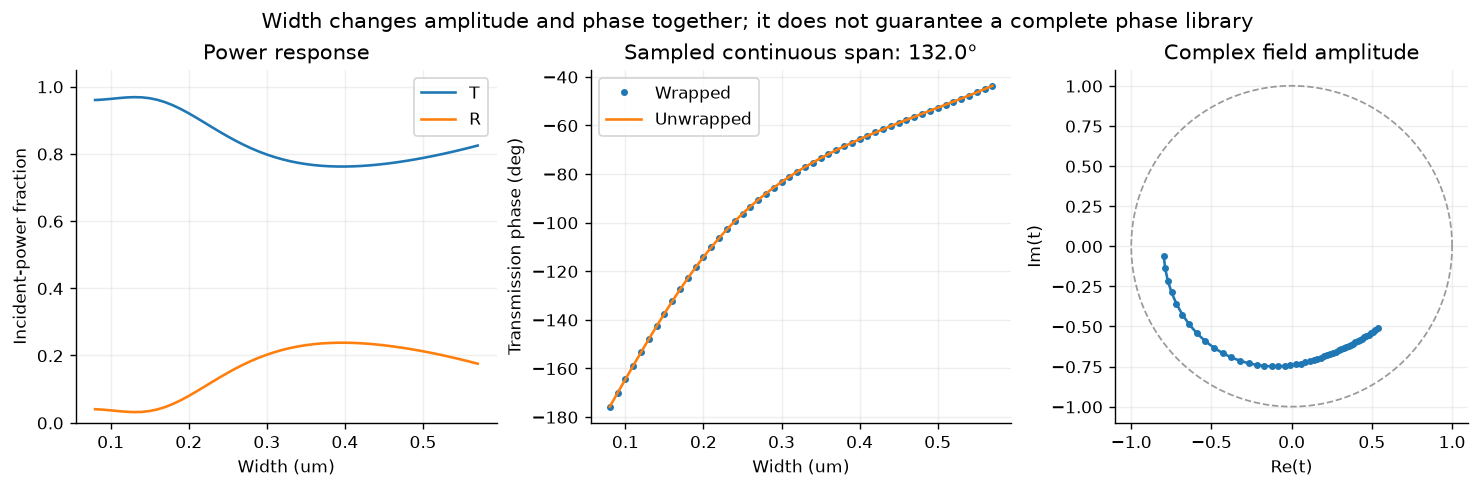

In [6]:
fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
axes[0].plot(WIDTHS_UM,T_values,label='T');axes[0].plot(WIDTHS_UM,[r['R'] for r in rows],label='R')
axes[0].set(xlabel='Width (um)',ylabel='Incident-power fraction',ylim=(0,1.05),title='Power response');axes[0].legend()
axes[1].plot(WIDTHS_UM,[r['phase_deg'] for r in rows],'.',label='Wrapped')
axes[1].plot(WIDTHS_UM,unwrapped,label='Unwrapped')
axes[1].set(xlabel='Width (um)',ylabel='Transmission phase (deg)',title=f'Sampled continuous span: {phase_span:.1f}°');axes[1].legend()
axes[2].plot(t_values.real,t_values.imag,'o-',ms=3)
theta=np.linspace(0,2*np.pi,200);axes[2].plot(np.cos(theta),np.sin(theta),'--',color='0.6',lw=1)
axes[2].set(xlabel='Re(t)',ylabel='Im(t)',title='Complex field amplitude',aspect='equal',xlim=(-1.1,1.1),ylim=(-1.1,1.1))
for ax in axes: ax.grid(alpha=.2)
fig.suptitle('Width changes amplitude and phase together; it does not guarantee a complete phase library')
plt.show()

## 5. Check the spectral neighborhood

The exported library is valid at one wavelength and incidence angle. This
separate sweep evaluates three widths over $1.35$-$1.75$ um to show why phase
and transmission should be retained together. It is not an extension of the
exported library's validated domain. A new library requires new row-wise
convergence checks at its own wavelengths and angles. The constant material
indices here deliberately exclude material dispersion.

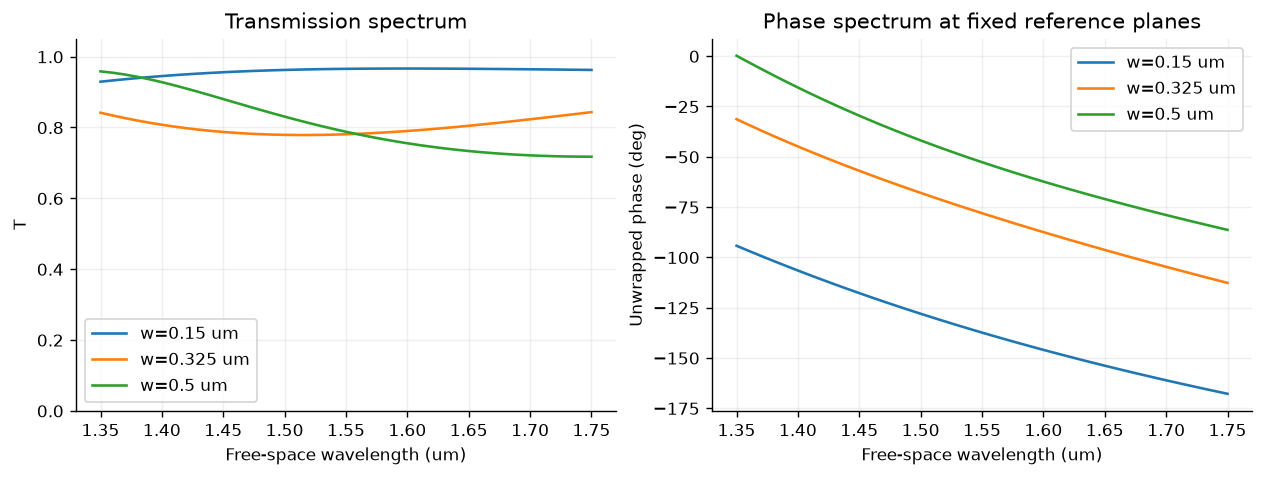

In [7]:
wavelengths=np.linspace(1.35,1.75,41)
fig,axes=plt.subplots(1,2,figsize=(10,3.7),layout='constrained')
for width in [.15,.325,.50]:
    results=[solve_cell(replace(REFERENCE,width_um=width,wavelength_um=float(w)),M_LIBRARY) for w in wavelengths]
    transmissions=np.array([v['t'][M_LIBRARY] for v in results])
    axes[0].plot(wavelengths,[v['T_total'] for v in results],label=f'w={width:g} um')
    axes[1].plot(wavelengths,np.rad2deg(np.unwrap(np.angle(transmissions))),label=f'w={width:g} um')
    assert max(v['balance_error'] for v in results)<1e-8
axes[0].set(ylabel='T',ylim=(0,1.05),title='Transmission spectrum')
axes[1].set(ylabel='Unwrapped phase (deg)',title='Phase spectrum at fixed reference planes')
for ax in axes: ax.set_xlabel('Free-space wavelength (um)');ax.grid(alpha=.2);ax.legend()
plt.show()

## 6. Select a design, and report an unattainable request honestly

For desired phase $\phi_\star$, use the circular error
$\Delta\phi=\arg(t e^{-i\phi_\star})$.
First retain only accepted rows with $T\geq0.8$, then minimize $|\Delta\phi|$.
The proposal is feasible only if the residual is within $5^\circ$.
A nearest row always exists in a nonempty library; a satisfactory design may not.
This is discrete selection, not a full metasurface optimization.

In [8]:
eligible=[row for row in rows if row['accepted'] and row['T']>=MIN_T_FOR_SELECTION]
selection=[]
for target in [-160.,-100.,-50.,0.]:
    if not eligible:
        selection.append([target,'none','none','none','no eligible geometry']);continue
    candidate=min(eligible,key=lambda row:abs(phase_error_deg(complex(row['t_real'],row['t_imag']),np.exp(1j*np.deg2rad(target)))))
    error=abs(phase_error_deg(complex(candidate['t_real'],candidate['t_imag']),np.exp(1j*np.deg2rad(target))))
    selection.append([target,candidate['width_um'],candidate['T'],error,'feasible' if error<=TARGET_TOL_DEG else 'target unmet'])
table(['Target phase (deg)','Nearest eligible width (um)','T','Circular error (deg)','Decision'],selection)

Target phase (deg),Nearest eligible width (um),T,Circular error (deg),Decision
-160,0.11,0.965621,1.06769,feasible
-100,0.24,0.864867,0.504068,feasible
-50,0.53,0.80191,0.989266,feasible
0,0.57,0.824494,43.7329,target unmet


## 7. A monitor shift changes phase without changing a device

A monitor in the incident medium sits at $z=-L_i$ and an output monitor at
$z=h+L_t$. Ratios referenced to incident field at the first monitor obey
$r_{\rm mon}=r e^{2ik_0q_iL_i}$ and
$t_{\rm mon}=t e^{ik_0(q_iL_i+q_tL_t)}$.
The next cell synthesizes these monitor shifts from the computed amplitudes
and removes them. This is an algebraic phase-reference test; RCWA itself
matches directly at the interfaces and does not use displaced monitors.

In [9]:
result=solve_cell(REFERENCE,M_LIBRARY)
r,t=result['r'][M_LIBRARY],result['t'][M_LIBRARY]
qi,qt=result['qi'][M_LIBRARY],result['qt'][M_LIBRARY]
k0=2*np.pi/REFERENCE.wavelength_um
monitor_rows=[]
for Li,Lt in [(0.,0.),(.1,.2),(.3,.4)]:
    rm=r*np.exp(2j*k0*qi*Li)
    tm=t*np.exp(1j*k0*(qi*Li+qt*Lt))
    rd,td=deembed_te(rm,tm,REFERENCE.wavelength_um,qi,qt,Li,Lt)
    assert max(abs(rd-r),abs(td-t))<1e-12
    monitor_rows.append([Li,Lt,np.rad2deg(np.angle(tm)),np.rad2deg(np.angle(td)),abs(td-t)])
table(['Li (um)','Lt (um)','Raw monitor t phase (deg)','Face-referenced phase (deg)','Complex error'],monitor_rows)

Li (um),Lt (um),Raw monitor t phase (deg),Face-referenced phase (deg),Complex error
0,0,-78.1108,-78.1108,0
0.1,0.2,14.7924,-78.1108,1.11022e-16
0.3,0.4,130.921,-78.1108,1.24127e-16


## 8. Optional Jupyter controls

Set `ENABLE_WIDGETS=True` in the parameter cell and rerun to inspect the
computed library in Jupyter. These controls select already calculated rows;
they do not solve a new electromagnetic problem. The published lab also has
a browser explorer for these data, without a Python installation.

In [10]:
if ENABLE_WIDGETS:
    import ipywidgets as widgets
    def inspect_width(index):
        row=rows[index]
        table(['Width (um)','T','Phase (deg)','Delta complex t'],[[row['width_um'],row['T'],row['phase_deg'],row['delta_t']]])
    display(widgets.interactive(inspect_width,index=widgets.IntSlider(value=25,min=0,max=len(rows)-1,description='Width row')))
else:
    print('Saved reference: optional Jupyter widgets disabled; use the browser library explorer or enable them locally.')

Saved reference: optional Jupyter widgets disabled; use the browser library explorer or enable them locally.


## What this run establishes, and what remains open

The saved run executes a full-wave TE ridge calculation, independent analytical
film checks, width-wise harmonic refinements, field reconstruction, and a
reusable library with explicit phase references. `scripts/validate_chapter03.py`
adds multiorder and mirror checks, a higher-order spot audit, and an optional
comparison with the separately developed grcwa implementation. The published
`data/chapter-03/validation.json` records that audit and its environment.

Exercise 1: explain why $|t|^2$ and $T$ differ when $n_i\ne n_t$.
Exercise 2: compare the $M=0$ power residual and complex-response error.
Exercise 3: rerun a different height and reassess phase coverage and feasibility.
Exercise 4: change incidence, identify all open orders, and repeat convergence.
Exercise 5: create a small supercell with differing neighbors using another
appropriate solver and assess the local-periodicity assumption; no such
supercell result is claimed here. Exercise 6: define train/test geometry groups
before extending this dataset for Chapter 10.

References: [Moharam and Gaylord (1981)](https://doi.org/10.1364/JOSA.71.000811),
[grcwa usage and conventions](https://grcwa.readthedocs.io/en/latest/usage.html),
and [Meep mode decomposition, phase references, and grating examples](https://meep.readthedocs.io/en/latest/Python_Tutorials/Mode_Decomposition/).
The course solver is an original restricted TE implementation, not the grcwa
package. Agreement between two RCWA implementations does not constitute an
independent FDTD/FEM comparison or experimental validation.